In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/water_potability_cleaned.csv")

print("Dataset shape:", df.shape)

Dataset shape: (3276, 10)


In [2]:
correlation_matrix = df.corr(numeric_only=True)

print("\nCorrelation Matrix:")
print(correlation_matrix)


Correlation Matrix:
                       ph  Hardness    Solids  Chloramines   Sulfate  \
ph               1.000000  0.075760 -0.082004    -0.031741  0.014178   
Hardness         0.075760  1.000000 -0.046899    -0.030054 -0.092833   
Solids          -0.082004 -0.046899  1.000000    -0.070148 -0.149747   
Chloramines     -0.031741 -0.030054 -0.070148     1.000000  0.023762   
Sulfate          0.014178 -0.092833 -0.149747     0.023762  1.000000   
Conductivity     0.017466 -0.023915  0.013831    -0.020486 -0.014182   
Organic_carbon   0.040240  0.003610  0.010242    -0.012653  0.027102   
Trihalomethanes  0.003145 -0.012707 -0.008799     0.016614 -0.025657   
Turbidity       -0.036107 -0.014449  0.019546     0.002363 -0.009767   
Potability      -0.003014 -0.013837  0.033743     0.023779 -0.020476   

                 Conductivity  Organic_carbon  Trihalomethanes  Turbidity  \
ph                   0.017466        0.040240         0.003145  -0.036107   
Hardness            -0.023915   

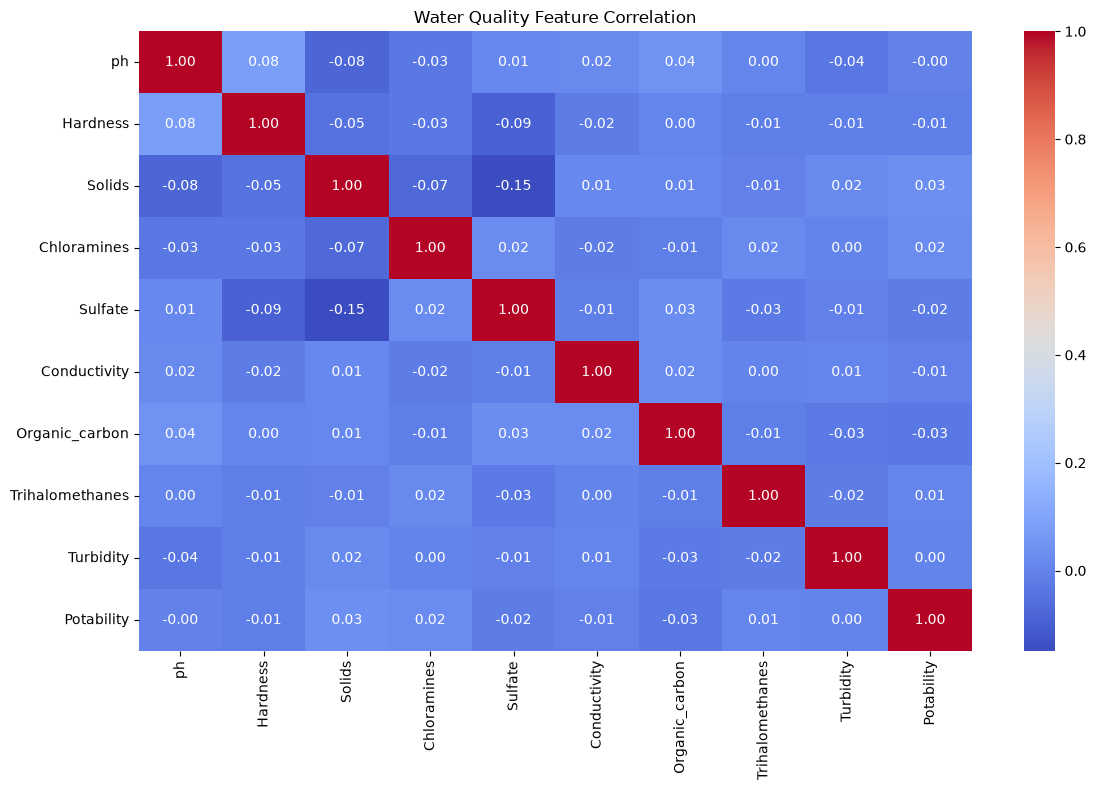

In [3]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Water Quality Feature Correlation")

plt.tight_layout()
plt.show()

In [4]:
potability_corr = (
    correlation_matrix["Potability"]
    .sort_values(ascending=False)
)

print("\nCorrelation with Potability:")
print(potability_corr)


Correlation with Potability:
Potability         1.000000
Solids             0.033743
Chloramines        0.023779
Trihalomethanes    0.006887
Turbidity          0.001581
ph                -0.003014
Conductivity      -0.008128
Hardness          -0.013837
Sulfate           -0.020476
Organic_carbon    -0.030001
Name: Potability, dtype: float64


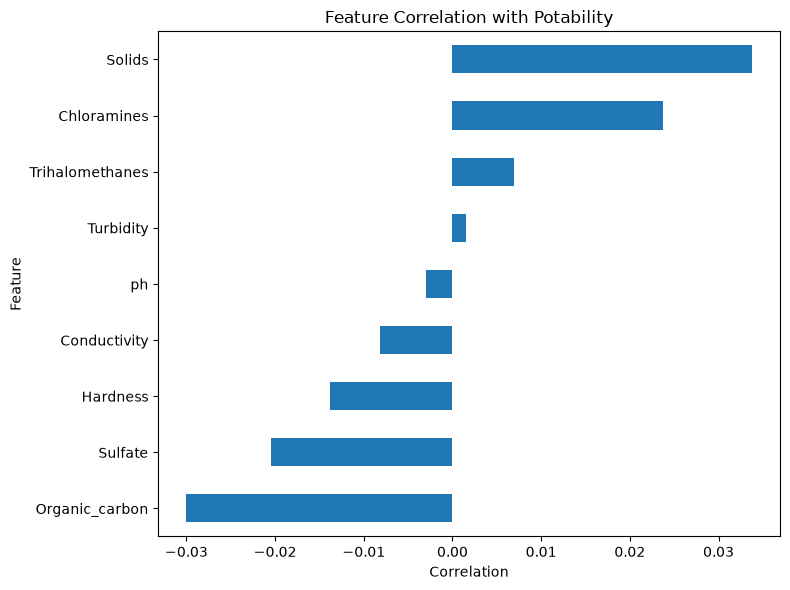

In [5]:
plt.figure(figsize=(8, 6))

potability_corr.drop("Potability").sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Potability")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [6]:
feature_corr = df.drop(columns=["Potability"]).corr()

print("\nHighly correlated feature pairs:")

for i in range(len(feature_corr.columns)):

    for j in range(i + 1, len(feature_corr.columns)):

        correlation = feature_corr.iloc[i, j]

        if abs(correlation) >= 0.7:

            print(
                feature_corr.columns[i],
                "<->",
                feature_corr.columns[j],
                ":",
                round(correlation, 3)
            )


Highly correlated feature pairs:
